# Deux fois plus de photos, même recette

Même séparation que `split_par_photo.ipynb` (par photo d'origine, 70 / 15 / 15, variantes en entraînement seulement), même architecture et même recette, modèle réentraîné. Une seule chose change : le jeu.

`dataset-v2` réunit les 250 photos d'origine du projet et 465 photos d'empreintes prises sur iNaturalist, sous licence libre (CC0, CC BY, CC BY-NC), triées à la main : 55 photos d'origine par espèce, 715 en tout, chacune avec ses cinq variantes (même code que `modeling.ipynb`). Auteurs et licences : `inat_attributions.csv`. Les images ne sont pas dans le dépôt ; pour reconstruire le jeu : `python fetch_inat.py`, puis `python build_dataset.py dataset inat dataset-v2`.

La dernière cellule donne aussi le score séparément sur les photos d'origine du projet et sur les photos iNaturalist.

In [1]:
import os, re, json
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix
import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.layers import Input, Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.models import Model
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras import Sequential, layers

dataset_path = "dataset-v2"
seed = 12  # Même graine que le notebook d'origine
batch_size = 16
img_size = (256, 256)
tf.keras.utils.set_random_seed(seed)

## 1. Rattacher chaque variante à sa photo d'origine

In [2]:
AUG = re.compile(r"^aug_(bright|flip|noise|rot|zoom)_")
class_names = sorted(d for d in os.listdir(dataset_path) if os.path.isdir(os.path.join(dataset_path, d)))

files = []  # (classe, fichier, photo d'origine)
for c in class_names:
    for f in sorted(os.listdir(os.path.join(dataset_path, c))):
        files.append((c, f, AUG.sub("", f)))

originals = {(c, f) for c, f, src in files if f == src}
assert all((c, src) in originals for c, f, src in files), "une variante sans photo d'origine"
print(len(files), "images,", len(originals), "photos d'origine,", len(class_names), "espèces")

4290 images, 715 photos d'origine, 13 espèces


## 2. Regrouper les photos d'origine presque identiques

Le MD5 du notebook de modélisation ne retire que les copies exactes. Une même photo enregistrée en `.jpg` et en `.png`, ou recadrée, passe au travers. On compare une empreinte visuelle (dHash 64 bits) de chaque paire de photos d'origine : à 6 bits d'écart ou moins, elles vont dans le même groupe, donc du même côté de la séparation.

Ici, deux paires sont signalées, d'une espèce à l'autre. Vérifiées à l'œil : ce sont des photos différentes, peu détaillées (neige, sol uniforme), que l'empreinte visuelle confond. Les regrouper les garde seulement du même côté de la séparation ; la mesure n'en souffre pas.

In [3]:
def dhash(path):
    g = np.asarray(Image.open(path).convert("L").resize((9, 8), Image.BILINEAR), dtype=np.int16)
    return (g[:, 1:] > g[:, :-1]).flatten()

orig = sorted(originals)
hashes = np.array([dhash(os.path.join(dataset_path, c, f)) for c, f in orig])
parent = list(range(len(orig)))
def root(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]; i = parent[i]
    return i

pairs = []
for i in range(len(orig)):
    d = (hashes[i + 1:] != hashes[i]).sum(axis=1)
    for j in np.flatnonzero(d <= 6) + i + 1:
        pairs.append((orig[i], orig[j], int(d[j - i - 1])))
        parent[root(j)] = root(i)

for a, b, d in pairs:
    print(f"{d:2d} bits  {a[0]}/{a[1]}  ~  {b[0]}/{b[1]}")
cross = [(a, b) for a, b, _ in pairs if a[0] != b[0]]
print(len(pairs), "paires presque identiques, dont", len(cross), "entre deux espèces différentes")
group = {o: root(i) for i, o in enumerate(orig)}

 6 bits  Chat/inat_735743851.jpg  ~  Lapin/inat_617482428.jpg
 5 bits  Lapin/inat_617482428.jpg  ~  Rat/inat_248440698.jpeg
2 paires presque identiques, dont 2 entre deux espèces différentes


## 3. Séparer par groupe, espèce par espèce

In [4]:
rng = np.random.default_rng(seed)
split = {}
for c in class_names:
    groups = sorted({g for (cc, _), g in group.items() if cc == c})
    rng.shuffle(groups)
    n_test = max(1, round(len(groups) * 0.15))
    n_val = max(1, round(len(groups) * 0.15))
    for k, g in enumerate(groups):
        split.setdefault(g, "test" if k < n_test else "val" if k < n_test + n_val else "train")

sets = {"train": [], "val": [], "test": []}
for c, f, src in files:
    s = split[group[(c, src)]]
    if s == "train" or f == src:  # les variantes augmentées ne vont qu'en entraînement
        sets[s].append((os.path.join(dataset_path, c, f), class_names.index(c)))

# Contrôle : aucun groupe, donc aucune photo d'origine, de part et d'autre de la séparation
grp = {os.path.join(dataset_path, c, f): group[(c, src)] for c, f, src in files}
g = {s: {grp[p] for p, _ in items} for s, items in sets.items()}
assert not (g["train"] & g["val"] or g["train"] & g["test"] or g["val"] & g["test"])
for s, items in sets.items():
    print(f"{s:5s} {len(items):5d} images", np.bincount([y for _, y in items], minlength=len(class_names)))

train  3036 images [234 234 234 234 234 234 234 234 234 234 228 234 234]
val     105 images [8 8 8 8 8 8 8 8 8 8 9 8 8]
test    104 images [8 8 8 8 8 8 8 8 8 8 8 8 8]


In [5]:
def load(items):
    # Même redimensionnement que image_dataset_from_directory : bilinéaire, sans recadrage
    x = np.stack([np.asarray(Image.open(p).convert("RGB").resize(img_size, Image.BILINEAR), dtype=np.uint8) for p, _ in items])
    y = tf.keras.utils.to_categorical([lbl for _, lbl in items], len(class_names))
    return x, y

(x_train, y_train), (x_val, y_val), (x_test, y_test) = load(sets["train"]), load(sets["val"]), load(sets["test"])
to_float = lambda x, y: (tf.cast(x, tf.float32), y)  # pixels 0-255 en float, comme image_dataset_from_directory
train_ds = tf.data.Dataset.from_tensor_slices((x_train, y_train)).shuffle(len(x_train), seed=seed).batch(batch_size).map(to_float)
validation_ds = tf.data.Dataset.from_tensor_slices((x_val, y_val)).batch(batch_size).map(to_float)

## 4. La même architecture que `pretrained_cnn_model.ipynb`, réentraînée

In [6]:
data_augmentation = Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomBrightness(0.2),
    layers.GaussianNoise(0.05),
])

inputs = Input(shape=(256, 256, 3))
x = data_augmentation(inputs)
base_model = ResNet50(weights="imagenet", include_top=False, input_tensor=x)
base_model.trainable = False
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dropout(0.5)(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)
predictions = Dense(len(class_names), activation="softmax")(x)
model = Model(inputs=inputs, outputs=predictions)

early_stop = EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True)
model.compile(optimizer=Adam(learning_rate=1e-3), loss="categorical_crossentropy", metrics=["accuracy"])
history = model.fit(train_ds, validation_data=validation_ds, epochs=10, callbacks=[early_stop], verbose=2)

Epoch 1/10
190/190 - 162s - 855ms/step - accuracy: 0.1380 - loss: 2.5810 - val_accuracy: 0.1810 - val_loss: 2.4318
Epoch 2/10
190/190 - 131s - 689ms/step - accuracy: 0.2207 - loss: 2.3065 - val_accuracy: 0.2095 - val_loss: 2.4139
Epoch 3/10
190/190 - 1809s - 10s/step - accuracy: 0.2875 - loss: 2.1134 - val_accuracy: 0.2190 - val_loss: 2.3655
Epoch 4/10
190/190 - 44s - 229ms/step - accuracy: 0.3297 - loss: 2.0003 - val_accuracy: 0.2571 - val_loss: 2.3671
Epoch 5/10
190/190 - 42s - 221ms/step - accuracy: 0.3910 - loss: 1.8375 - val_accuracy: 0.2571 - val_loss: 2.4527
Epoch 6/10
190/190 - 42s - 222ms/step - accuracy: 0.4127 - loss: 1.7753 - val_accuracy: 0.2190 - val_loss: 2.4965
Epoch 7/10
190/190 - 40s - 213ms/step - accuracy: 0.4302 - loss: 1.6824 - val_accuracy: 0.2476 - val_loss: 2.4909
Epoch 8/10
190/190 - 39s - 208ms/step - accuracy: 0.4654 - loss: 1.5949 - val_accuracy: 0.2762 - val_loss: 2.4866
Epoch 9/10
190/190 - 40s - 209ms/step - accuracy: 0.4760 - loss: 1.5717 - val_accuracy

In [7]:
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
model.compile(optimizer=Adam(learning_rate=1e-5), loss="categorical_crossentropy", metrics=["accuracy"])
history_finetune = model.fit(train_ds, validation_data=validation_ds, epochs=20, callbacks=[early_stop], verbose=2)

Epoch 1/20
190/190 - 74s - 390ms/step - accuracy: 0.2764 - loss: 2.1310 - val_accuracy: 0.2000 - val_loss: 2.3882
Epoch 2/20
190/190 - 55s - 287ms/step - accuracy: 0.3419 - loss: 1.9408 - val_accuracy: 0.2190 - val_loss: 2.3941
Epoch 3/20
190/190 - 55s - 291ms/step - accuracy: 0.3798 - loss: 1.8534 - val_accuracy: 0.2381 - val_loss: 2.4353
Epoch 4/20
190/190 - 55s - 291ms/step - accuracy: 0.4252 - loss: 1.7273 - val_accuracy: 0.2571 - val_loss: 2.4779
Epoch 5/20
190/190 - 55s - 288ms/step - accuracy: 0.4592 - loss: 1.6396 - val_accuracy: 0.2571 - val_loss: 2.4670
Epoch 6/20
190/190 - 55s - 289ms/step - accuracy: 0.4816 - loss: 1.5431 - val_accuracy: 0.2571 - val_loss: 2.4906
Epoch 7/20
190/190 - 55s - 291ms/step - accuracy: 0.5293 - loss: 1.4267 - val_accuracy: 0.2667 - val_loss: 2.5708
Epoch 8/20
190/190 - 55s - 288ms/step - accuracy: 0.5451 - loss: 1.3726 - val_accuracy: 0.2857 - val_loss: 2.5800
Epoch 9/20
190/190 - 55s - 289ms/step - accuracy: 0.5876 - loss: 1.2331 - val_accuracy: 

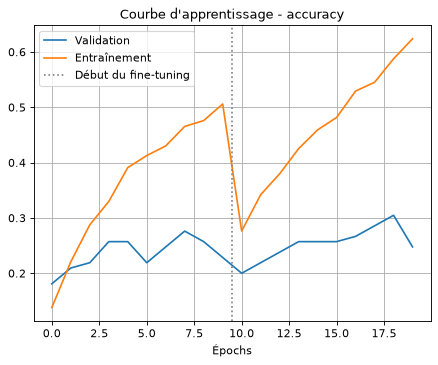

In [8]:
plt.plot(history.history["val_accuracy"] + history_finetune.history["val_accuracy"], label="Validation")
plt.plot(history.history["accuracy"] + history_finetune.history["accuracy"], label="Entraînement")
plt.axvline(len(history.history["accuracy"]) - 0.5, color="grey", ls=":", label="Début du fine-tuning")
plt.title("Courbe d'apprentissage - accuracy"); plt.xlabel("Épochs"); plt.legend(); plt.grid(True); plt.show()

## 5. Évaluation, une seule fois, sur le jeu de test

Le test compte 104 photos d'origine, 8 par espèce : l'intervalle à 95 % est calculé par bootstrap, 2 000 tirages avec remise.

In [9]:
def evaluate(x, y):
    y_true = y.argmax(axis=1)
    y_pred = model.predict(x.astype("float32"), batch_size=batch_size, verbose=0).argmax(axis=1)
    return y_true, y_pred

def bootstrap(y_true, y_pred, metric, n=2000):
    r = np.random.default_rng(seed)
    idx = r.integers(0, len(y_true), (n, len(y_true)))
    vals = [metric(y_true[i], y_pred[i]) for i in idx]
    return np.percentile(vals, [2.5, 97.5])

macro_f1 = lambda t, p: f1_score(t, p, average="macro", labels=range(len(class_names)), zero_division=0)
results = {}
for name, (x, y) in {"validation": (x_val, y_val), "test": (x_test, y_test)}.items():
    t, p = evaluate(x, y)
    results[name] = dict(n=len(t), accuracy=accuracy_score(t, p), f1_macro=macro_f1(t, p),
                         accuracy_ic95=bootstrap(t, p, accuracy_score).tolist(), f1_macro_ic95=bootstrap(t, p, macro_f1).tolist())
    print(f"{name:10s} n={len(t):3d}  accuracy {results[name]['accuracy']:.3f} {np.round(results[name]['accuracy_ic95'], 3)}"
          f"  F1 macro {results[name]['f1_macro']:.3f} {np.round(results[name]['f1_macro_ic95'], 3)}")
y_true, y_pred = t, p  # test

validation n=105  accuracy 0.200 [0.124 0.286]  F1 macro 0.189 [0.115 0.252]
test       n=104  accuracy 0.260 [0.183 0.346]  F1 macro 0.242 [0.162 0.305]


              precision    recall  f1-score   support

      Castor       0.20      0.25      0.22         8
        Chat       0.20      0.25      0.22         8
       Chien       0.00      0.00      0.00         8
      Coyote       0.27      0.38      0.32         8
    Ecureuil       0.57      0.50      0.53         8
       Lapin       0.60      0.38      0.46         8
        Loup       0.22      0.50      0.31         8
        Lynx       0.29      0.25      0.27         8
        Ours       0.00      0.00      0.00         8
        Puma       0.00      0.00      0.00         8
         Rat       0.12      0.12      0.12         8
Raton laveur       0.33      0.38      0.35         8
      Renard       0.30      0.38      0.33         8

    accuracy                           0.26       104
   macro avg       0.24      0.26      0.24       104
weighted avg       0.24      0.26      0.24       104



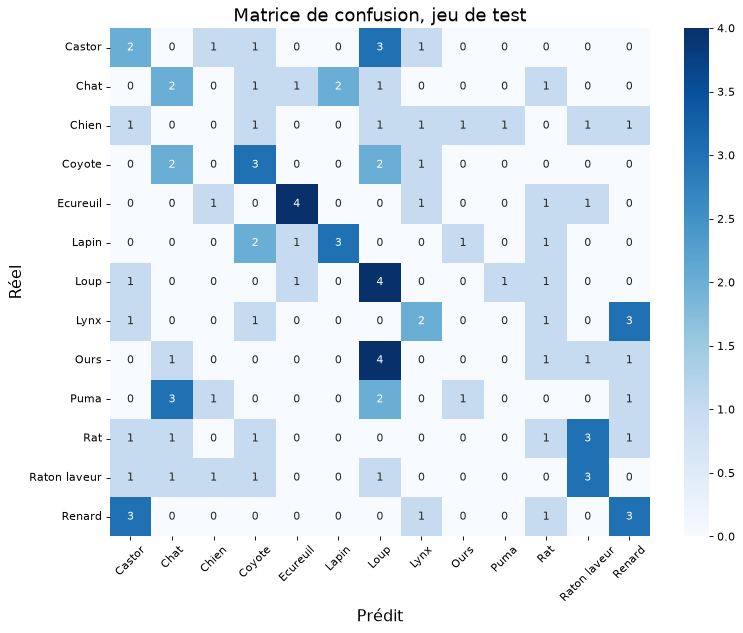

In [10]:
print(classification_report(y_true, y_pred, labels=range(len(class_names)), target_names=class_names, zero_division=0))
cm = confusion_matrix(y_true, y_pred, labels=range(len(class_names)))
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédit", fontsize=14); plt.ylabel("Réel", fontsize=14)
plt.title("Matrice de confusion, jeu de test", fontsize=16)
plt.xticks(rotation=45); plt.yticks(rotation=0); plt.tight_layout(); plt.show()
with open("resultats_split_par_photo_v2.json", "w") as f:
    json.dump(results, f, indent=2)

## Conclusion

Sur 104 photos de test jamais vues, le modèle donne **26 %** de bonnes réponses (intervalle à 95 % : 18 % à 35 %) et un F1 macro de 0,24 (0,16 à 0,31). Au hasard, sur 13 espèces, on aurait 8 %.

Avec 715 photos d'origine au lieu de 250 : aucun gain visible, au plus quelques points. Les deux tests (38 puis 104 photos) ne sont pas les mêmes et leurs intervalles se recouvrent ; la mesure est seulement plus précise (18 à 35 % au lieu de 13 à 39 %). Sur les photos d'origine du projet : 25 % (48 photos, 13 à 38 %) ; sur les photos iNaturalist : 27 % (56 photos, 16 à 39 %). Ces deux scores ne se distinguent pas.

L'arrêt anticipé garde les poids de la plus faible perte de validation : ceux de la première passe de fine-tuning (perte 2,39, 2,56 au hasard ; justesse de validation 20 %, alors qu'elle montait ensuite vers 30 %). Le modèle évalué est donc peu entraîné.

Le nombre de photos n'était donc pas le seul frein. Pistes suivantes : choisir le modèle sur la justesse de validation, recadrer l'empreinte avant de la classer, un fine-tuning plus large. Un seul entraînement, graine 12 : la variation d'un entraînement à l'autre n'est pas mesurée.

In [11]:
# Par source : les photos d'origine du projet (comparables aux 26 % d'avant) et les photos iNaturalist ajoutées
src_test = np.array(["inat" if os.path.basename(p).startswith("inat_") else "origine" for p, _ in sets["test"]])
for s in ("origine", "inat"):
    m = src_test == s
    results["test_" + s] = dict(n=int(m.sum()), accuracy=accuracy_score(y_true[m], y_pred[m]), accuracy_ic95=bootstrap(y_true[m], y_pred[m], accuracy_score).tolist())
    print(f"test {s:8s} n={m.sum():3d}  accuracy {results['test_' + s]['accuracy']:.3f} {np.round(results['test_' + s]['accuracy_ic95'], 3)}")
with open("resultats_split_par_photo_v2.json", "w") as f:
    json.dump(results, f, indent=2)


test origine  n= 48  accuracy 0.250 [0.125 0.375]
test inat     n= 56  accuracy 0.268 [0.161 0.393]
